# Part 3 of 6: Vision Transformer: Fine-Tuning Strategies

COMP7015 Group Project – Topic 1: Plant Disease Classification. This notebook covers Section 10: three fine-tuning strategies for a pre-trained ViT-B/16 and an augmentation ablation, following Zhouyang's protocol, and the selection of the final ViT on the validation set.

The notebooks run in order: `01_data` → `02_cnn_resnet` → `03_vit` → `04_test_evaluation` → `05_robustness` → `06_discussion`. The shared code lives in the `plantdisease/` package. Finished training runs and predictions are saved under `OUT_DIR/runs/` and reused, so this notebook can be re-run on its own once the earlier ones have run.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import f1_score

from plantdisease.config import SHORT_NAMES, TRAIN_CONFIG, env, out_path
from plantdisease.data.dataset import prepare
from plantdisease.evaluate import (
    compare_seeds,
    mean_sd,
    sd,
    seed_scores,
    stable_errors,
    training_cost,
)
from plantdisease.experiments import register, save_selected
from plantdisease.models import build_model, count_params, set_trainable
from plantdisease.plots import finish, mean_and_sd, stack_curves
from plantdisease.predictions import predict_labels
from plantdisease.recipe import RunConfig
from plantdisease.train import run_seeds

data = prepare()  # leaf-group split of notebook 01, rebuilt from the image cache

## 10. ViT-B/16 Fine-Tuning

**Model.** torchvision's ViT-B/16 with ImageNet-1K weights. The 224×224 image is cut into 14×14 = 196 patches of 16×16 pixels; together with a class token they pass through 12 self-attention blocks that relate every patch to every other patch (Lab 5). The ImageNet head is replaced by a 4-class linear layer (3,076 parameters); the model has 85.8 M parameters in total.

**Fine-tuning strategies.** All strategies first train **only the new head for 3 epochs**. From epoch 4 they differ only in which parameters are unfrozen:

| Strategy | Epochs 1–3 | Epochs 4–15 |
|---|---|---|
| **head only** | head | head; the backbone stays frozen |
| **partial** | head | last 2 encoder blocks, final LayerNorm and head |
| **full** | head | every parameter, including patch embedding, position embedding and class token |

An **augmentation ablation** repeats the partial strategy without training augmentation. Retraining on grayscale and background-removed photos (Zhouyang's input ablation) follows in notebook 05, Section 15.

**Training settings.** 15 epochs, batch size 16, AdamW with weight decay 0.01, constant learning rates: head 1e-3 in epochs 1–3, then head 1e-4 and unfrozen backbone 1e-5 (two parameter groups; the optimizer is rebuilt at the switch). Cross-entropy without class weights, gradient-norm limit 1, mixed precision on CUDA, the checkpoint with the best validation macro-F1 is kept. **Early stopping** (an addition to Zhouyang's fixed 15 epochs): a run stops when the validation macro-F1 has not improved for 5 epochs of the fine-tuning stage, so strategies can train for different numbers of epochs; the tables report the epochs trained next to the training time. Seeds 62, 63 and 64; a strategy's three runs share the split, and the same seed gives the same initialisation and the same first three epochs for all strategies.

**Differences to Zhouyang's original runs.** The classes, the split and the preprocessing are the project's (notebook 01): the whole photo is resized to 224×224 instead of a 256 resize with a centre crop, and the training augmentation is the project's (flips, 90° rotations, mild brightness/contrast) instead of flips only. The "no augmentation" ablation switches this whole augmentation off.

### 10.0 The experiments

The four strategies are defined here as changes of one base recipe: partial fine-tuning of the last 2 encoder blocks. The base recipe follows the training settings above. `register` makes the experiments known by name to the other notebooks, which rebuild the models from the run names.

In [4]:
BASE_VIT = RunConfig(
    arch="vit_b_16",
    finetune="partial",
    trainable_blocks=2,
    lr=1e-5,  # unfrozen backbone parameters (after the head epochs)
    finetune_head_lr=1e-4,  # classifier head after the head epochs
    head_lr=1e-3,  # classifier head during the head epochs
    head_epochs=3,
    epochs=int(env("EPOCHS_VIT", 15)),
    patience=int(env("PATIENCE_VIT", 5)),  # counts only the epochs after the head-only epochs
    batch_size=16,
    weight_decay=0.01,
    scheduler="constant",
    class_weights=False,
    augment=True,
)
vit_experiments = {
    "ViT-B/16 head only": BASE_VIT.variant(finetune="head"),
    "ViT-B/16 partial (last 2 blocks)": BASE_VIT,
    "ViT-B/16 full fine-tuning": BASE_VIT.variant(finetune="full"),
    "ViT-B/16 partial, no augmentation": BASE_VIT.variant(augment=False),
}
register(vit_experiments)  # the other notebooks find the recipes by name


def changes_table(experiments, base):
    # What each experiment changes relative to the base recipe
    changes = {
        name: ", ".join(f"{k}={v}" for k, v in cfg.changes_from(base).items()) or "(base recipe)"
        for name, cfg in experiments.items()
    }
    return pd.Series(changes, name="changes from the base recipe").to_frame()


changes_table(vit_experiments, BASE_VIT)

,changes from the base recipe
ViT-B/16 head only,finetune=head
ViT-B/16 partial (last 2 blocks),(base recipe)
ViT-B/16 full fine-tuning,finetune=full
"ViT-B/16 partial, no augmentation",augment=False


### 10.1 Which parameters does each strategy train?

A check before training (as in Zhouyang's smoke test): the number of trainable parameters in each stage.

In [2]:
model = build_model(BASE_VIT)
total = count_params(model)
rows = []
for name, cfg in vit_experiments.items():
    row = {"run": name}
    for stage in ("head", "finetune"):
        set_trainable(model, cfg, stage)
        row[f"trainable, {stage} stage"] = count_params(model, trainable_only=True)
    row["share of all parameters"] = f"{row['trainable, finetune stage'] / total:.2%}"
    rows.append(row)
del model
pd.DataFrame(rows).set_index("run")

,"trainable, head stage","trainable, finetune stage",share of all parameters
run,,,
ViT-B/16 head only,3076,3076,0.00%
ViT-B/16 partial (last 2 blocks),3076,14180356,16.53%
ViT-B/16 full fine-tuning,3076,85801732,100.00%
"ViT-B/16 partial, no augmentation",3076,14180356,16.53%


### 10.2 Training

Every configuration is trained with all three seeds (4 configurations × 3 seeds = 12 runs).

In [3]:
vit_histories = {name: run_seeds(name, data) for name in vit_experiments}


===== ViT-B/16 head only (seed 62) =====
Epoch 1/15 [head] | train loss 0.3355 acc 0.8968 | val loss 0.1668 acc 0.9543 macro-F1 0.9542 | 29s
Epoch 2/15 [head] | train loss 0.1051 acc 0.9734 | val loss 0.0918 acc 0.9714 macro-F1 0.9709 | 16s
Epoch 3/15 [head] | train loss 0.0689 acc 0.9842 | val loss 0.0699 acc 0.9786 macro-F1 0.9780 | 17s
Epoch 4/15 [finetune] | train loss 0.0514 acc 0.9876 | val loss 0.0610 acc 0.9843 macro-F1 0.9836 | 17s
Epoch 5/15 [finetune] | train loss 0.0483 acc 0.9904 | val loss 0.0597 acc 0.9814 macro-F1 0.9806 | 17s
Epoch 6/15 [finetune] | train loss 0.0465 acc 0.9907 | val loss 0.0582 acc 0.9829 macro-F1 0.9820 | 17s
Epoch 7/15 [finetune] | train loss 0.0451 acc 0.9917 | val loss 0.0553 acc 0.9843 macro-F1 0.9836 | 17s
Epoch 8/15 [finetune] | train loss 0.0441 acc 0.9904 | val loss 0.0545 acc 0.9829 macro-F1 0.9820 | 17s
Epoch 9/15 [finetune] | train loss 0.0453 acc 0.9914 | val loss 0.0526 acc 0.9857 macro-F1 0.9850 | 17s
Epoch 10/15 [finetune] | train los

e:\Projects_2026\COMP7015_AI_Group_Project5-main\.venv\Lib\site-packages\torch\autograd\graph.py:1113: UserWarning: Flash Attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\transformers\cuda\attention_backward.cu:159.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 4/15 [finetune] | train loss 0.0420 acc 0.9876 | val loss 0.0378 acc 0.9886 macro-F1 0.9877 | 20s
Epoch 5/15 [finetune] | train loss 0.0201 acc 0.9947 | val loss 0.0393 acc 0.9857 macro-F1 0.9839 | 20s
Epoch 6/15 [finetune] | train loss 0.0113 acc 0.9975 | val loss 0.0169 acc 0.9957 macro-F1 0.9954 | 22s
Epoch 7/15 [finetune] | train loss 0.0090 acc 0.9978 | val loss 0.0145 acc 0.9957 macro-F1 0.9953 | 22s
Epoch 8/15 [finetune] | train loss 0.0061 acc 0.9981 | val loss 0.0125 acc 0.9957 macro-F1 0.9954 | 21s
Epoch 9/15 [finetune] | train loss 0.0050 acc 0.9988 | val loss 0.0097 acc 0.9971 macro-F1 0.9970 | 21s
Epoch 10/15 [finetune] | train loss 0.0017 acc 1.0000 | val loss 0.0124 acc 0.9957 macro-F1 0.9957 | 21s
Epoch 11/15 [finetune] | train loss 0.0023 acc 0.9994 | val loss 0.0097 acc 0.9971 macro-F1 0.9970 | 21s
Epoch 12/15 [finetune] | train loss 0.0015 acc 0.9997 | val loss 0.0067 acc 0.9986 macro-F1 0.9987 | 21s
Epoch 13/15 [finetune] | train loss 0.0006 acc 0.9997 | val l

### 10.3 Validation results, cost and selection

The final ViT is the configuration with the highest **mean validation macro-F1 over the seeds**. The table also shows the training cost: trainable parameters in the fine-tuning stage, epochs trained (early stopping), total training time (all epochs, without validation) and the peak memory during training.

In [4]:
rows = []
for name, hs in vit_histories.items():
    rows.append(
        {
            "run": name,
            "val macro-F1": mean_sd([max(h.val_f1) for h in hs]),
            "best epochs": ", ".join(str(int(np.argmax(h.val_f1)) + 1) for h in hs),
            **training_cost(name),
        }
    )
vit_validation = pd.DataFrame(rows).set_index("run")
vit_validation.to_csv(out_path("vit_validation.csv"))

mean_val = {
    n: np.mean([max(h.val_f1) for h in hs]) for n, hs in vit_histories.items()
}
BEST_VIT = max(mean_val, key=mean_val.get)
# OUT_DIR/final_models.json, read by notebooks 04-06
save_selected("vit_b_16", BEST_VIT)
print("Selected ViT:", BEST_VIT)
vit_validation

Selected ViT: ViT-B/16 full fine-tuning


,val macro-F1,best epochs,trainable params,epochs trained,train time (s),train s/epoch,peak memory (MiB)
run,,,,,,,
ViT-B/16 head only,0.9889 ± 0.0019,"10, 13, 15",3076,15.0 ± 0.0,235.1 ± 1.6,15.676605,701.041016
ViT-B/16 partial (last 2 blocks),0.9982 ± 0.0008,"12, 12, 10",14180356,15.0 ± 0.0,279.1 ± 6.1,18.609038,895.266602
ViT-B/16 full fine-tuning,1.0000 ± 0.0000,"5, 4, 4",85801732,9.3 ± 0.6,294.7 ± 27.8,31.533455,2555.576497
"ViT-B/16 partial, no augmentation",0.9932 ± 0.0008,"5, 7, 6",14180356,11.0 ± 1.0,205.4 ± 19.2,18.671374,895.266602


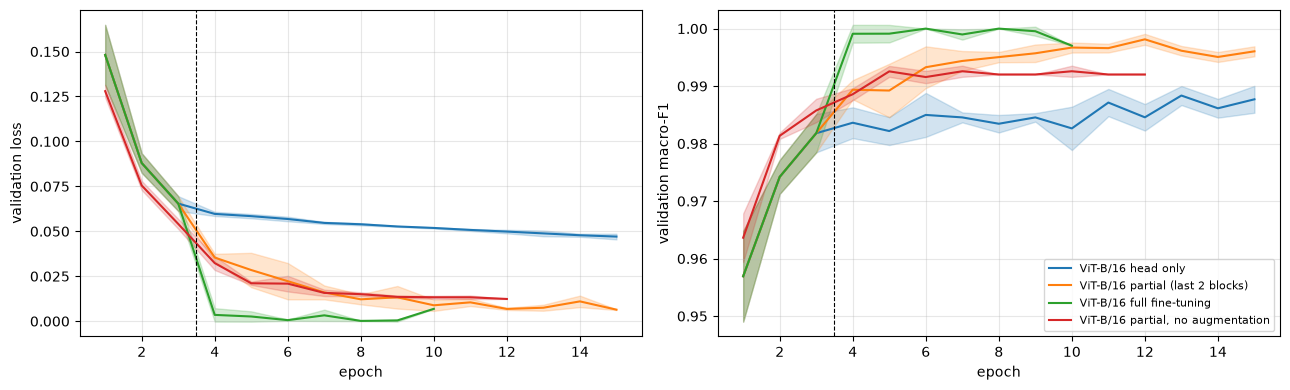

In [5]:
# Learning curves: mean over the seeds, shaded ± sd; dashed line: switch from head-only to fine-tuning
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k, (name, hs) in enumerate(vit_histories.items()):
    for ax, key in zip(axes, ("val_loss", "val_f1"), strict=True):
        values = stack_curves(hs, key)  # NaN after a seed stopped early
        epochs = np.arange(1, values.shape[1] + 1)
        mean, spread = mean_and_sd(values)
        ax.plot(epochs, mean, color=f"C{k}", label=name)
        ax.fill_between(epochs, mean - spread, mean + spread, color=f"C{k}", alpha=0.2)
for ax, label in zip(axes, ("validation loss", "validation macro-F1"), strict=True):
    ax.axvline(
        BASE_VIT.head_epochs + 0.5, color="black", linestyle="--", linewidth=0.8
    )
    ax.set_xlabel("epoch")
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
axes[1].legend(fontsize=8)
finish("vit_learning_curves.png")

### 10.4 Test results of all strategies (after selection)

The selection above uses only the validation set. Afterwards, every strategy is evaluated once on the test set, as in Zhouyang's comparison, to show what the strategies achieve and cost. Strategies trained with the same seed share the initialisation and the first three epochs, so they are also compared seed by seed. The table of errors counts the test photos that every seed misclassifies and those misclassified at least once.

In [6]:
y_test = data.y_test
vit_preds = predict_labels(vit_experiments, {"test": data.images[data.test_idx]})
test_f1 = seed_scores(vit_experiments, vit_preds, "test", y_test)
rows = []
for name in vit_experiments:
    preds = [vit_preds[(name, s, "test")] for s in TRAIN_CONFIG["seeds"]]
    rows.append(
        {
            "run": name,
            "test accuracy": mean_sd([(p == y_test).mean() for p in preds]),
            "test macro-F1": mean_sd(test_f1[name]),
            **stable_errors(preds, y_test),
            "train time (s)": training_cost(name)["train time (s)"],
            "peak memory (MiB)": training_cost(name)["peak memory (MiB)"],
        }
    )
vit_test = pd.DataFrame(rows).set_index("run")
vit_test.to_csv(out_path("vit_strategies_test.csv"))
vit_test

,test accuracy,test macro-F1,errors per seed,wrong in every seed,wrong at least once,train time (s),peak memory (MiB)
run,,,,,,,
ViT-B/16 head only,0.9869 ± 0.0029,0.9857 ± 0.0027,"11, 9, 7",7,12,235.1 ± 1.6,701.041016
ViT-B/16 partial (last 2 blocks),0.9947 ± 0.0008,0.9940 ± 0.0010,"4, 3, 4",3,4,279.1 ± 6.1,895.266602
ViT-B/16 full fine-tuning,0.9966 ± 0.0030,0.9966 ± 0.0031,"4, 0, 3",0,6,294.7 ± 27.8,2555.576497
"ViT-B/16 partial, no augmentation",0.9942 ± 0.0015,0.9937 ± 0.0016,"5, 4, 3",1,6,205.4 ± 19.2,895.266602


In [7]:
# Same-seed comparisons on the test set (A - B in macro-F1)
names = list(vit_experiments)
pairs = {
    "partial vs. head only": (names[1], names[0]),
    "full vs. partial": (names[2], names[1]),
    "augmentation vs. none (partial)": (names[1], names[3]),
}
vit_comparison = pd.DataFrame(
    {label: compare_seeds(test_f1[a], test_f1[b]) for label, (a, b) in pairs.items()}
).T
vit_comparison.to_csv(out_path("vit_strategy_comparison.csv"))
vit_comparison

,A - B (mean),A - B (sd),A higher in
partial vs. head only,0.008262,0.002959,3 of 3 seeds
full vs. partial,0.002576,0.00223,3 of 3 seeds
augmentation vs. none (partial),0.00032,0.001794,2 of 3 seeds


,healthy,Early_blight,Leaf_Mold,Spider_mites
ViT-B/16 head only,0.9943,0.9746,0.9813,0.9928
ViT-B/16 partial (last 2 blocks),1.0000,0.9875,0.9906,0.9980
ViT-B/16 full fine-tuning,1.0000,0.9932,0.9965,0.9967
"ViT-B/16 partial, no augmentation",1.0000,0.9864,0.9917,0.9967


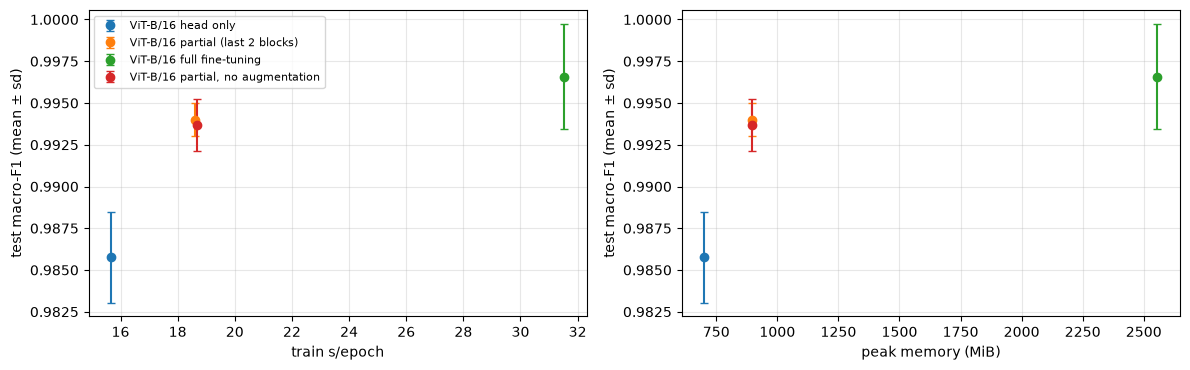

In [8]:
# Per-class test F1 (mean over seeds) and the accuracy-cost trade-off of the strategies
per_class = pd.DataFrame(
    {
        name: np.mean(
            [
                f1_score(y_test, vit_preds[(name, s, "test")], average=None)
                for s in TRAIN_CONFIG["seeds"]
            ],
            axis=0,
        )
        for name in vit_experiments
    },
    index=SHORT_NAMES,
).T
display(per_class.round(4))

cost = pd.DataFrame([training_cost(n) for n in vit_experiments], index=list(vit_experiments))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, column in zip(axes, ("train s/epoch", "peak memory (MiB)"), strict=True):
    for k, name in enumerate(vit_experiments):
        ax.errorbar(
            cost.at[name, column],
            test_f1[name].mean(),
            yerr=sd(test_f1[name]),
            fmt="o",
            color=f"C{k}",
            label=name,
            capsize=3,
        )
    ax.set_xlabel(column)
    ax.set_ylabel("test macro-F1 (mean ± sd)")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
finish("vit_strategy_cost.png")